# 01 — EDA (Corevent Analytics)

Overview of loaded tables (Postgres or synthetic fallback). Logic lives in `corevent_analytics`.

In [6]:
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from corevent_analytics.data import load_data, build_category_transactions, build_user_features

sns.set_theme(style="whitegrid")
tables, source = load_data()
print("source:", source)
{name: len(df) for name, df in tables.items()}

source: postgres


{'users': 114,
 'events': 33,
 'orders': 66,
 'order_items': 56,
 'favorites': 165,
 'tickets': 95,
 'event_ratings': 23,
 'ticket_types': 42}

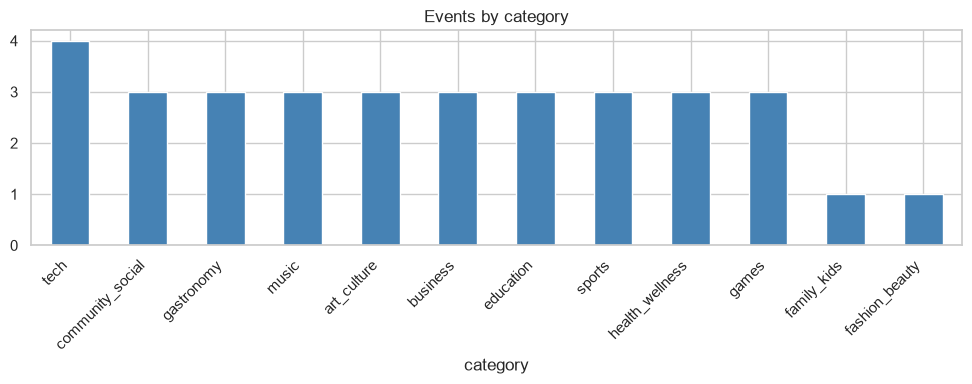

In [7]:
events = tables["events"]
fig, ax = plt.subplots(figsize=(10, 4))
events["category"].value_counts().plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Events by category")
ax.set_xlabel("category")
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
plt.show()

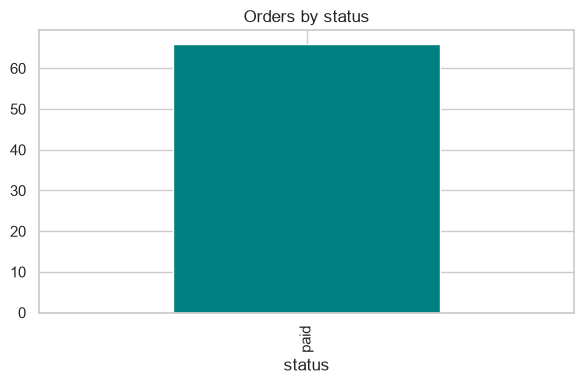

In [8]:
orders = tables["orders"]
if not orders.empty:
    fig, ax = plt.subplots(figsize=(6, 4))
    orders["status"].value_counts().plot(kind="bar", ax=ax, color="teal")
    ax.set_title("Orders by status")
    fig.tight_layout()
    plt.show()
else:
    print("No orders")

In [9]:
transactions = build_category_transactions(tables)
lengths = [len(t) for t in transactions]
print("n_transactions:", len(transactions))
print("avg categories/user:", sum(lengths) / len(lengths) if lengths else 0)

counter = Counter(cat for t in transactions for cat in t)
pd.Series(counter).sort_values(ascending=False).head(14)

n_transactions: 55
avg categories/user: 3.0


art_culture         17
tech                17
business            16
gastronomy          16
music               16
education           15
health_wellness     14
games               14
sports              13
community_social    13
fashion_beauty       7
family_kids          7
dtype: int64

In [10]:
features = build_user_features(tables)
features[["age", "n_orders", "n_favorites", "avg_ticket", "checkin_rate"]].describe()

,age,n_orders,n_favorites,avg_ticket,checkin_rate
count,114.000000,114.000000,114.000000,114.000000,114.000000
mean,36.270183,0.578947,1.447368,41.965643,0.054094
std,6.706239,0.763025,1.505695,74.215559,0.147905
min,21.147159,0.000000,0.000000,0.000000,0.000000
25%,36.856947,0.000000,0.000000,0.000000,0.000000
50%,36.856947,0.000000,0.000000,0.000000,0.000000
75%,36.856947,1.000000,3.000000,61.875000,0.000000
max,54.696783,3.000000,3.000000,435.000000,0.500000
